<center><img src='https://drive.google.com/uc?id=1_utx_ZGclmCwNttSe40kYA6VHzNocdET' height="60"></center>

AI TECH - Akademia Innowacyjnych Zastosowań Technologii Cyfrowych. Program Operacyjny Polska Cyfrowa na lata 2014-2020
<hr>

<center><img src='https://drive.google.com/uc?id=1BXZ0u3562N_MqCLcekI-Ens77Kk4LpPm'></center>

<center>
Projekt współfinansowany ze środków Unii Europejskiej w ramach Europejskiego Funduszu Rozwoju Regionalnego
Program Operacyjny Polska Cyfrowa na lata 2014-2020,
Oś Priorytetowa nr 3 "Cyfrowe kompetencje społeczeństwa" Działanie  nr 3.2 "Innowacyjne rozwiązania na rzecz aktywizacji cyfrowej"
Tytuł projektu:  „Akademia Innowacyjnych Zastosowań Technologii Cyfrowych (AI Tech)”
    </center>

Code based on https://github.com/pytorch/examples/blob/master/mnist/main.py

In this exercise, we are using high-level abstractions from torch.nn like nn.Linear.
Note: during the next lab session we will go one level deeper and implement more things
with bare hands.

Tasks:

 1. Read the code.

 2. Check that the given implementation reaches 95% test accuracy for architecture input-128-128-10 after few epochs.

 3. Add the option to use SGD with momentum instead of ADAM.

 4. Experiment with different learning rates. Use the provided TrainingVisualizer
 to plot the learning curves and gradient-to-weight ratios. Compare visualizations
 for different learning rates for both ADAM and SGD with momentum.

 5. Parameterize the constructor by a list of sizes of hidden layers of the MLP.
 Note that this requires creating a list of layers as an attribute of the Net class,
 and one can't use a standard Python list containing nn.Modules (why?).
 Check torch.nn.ModuleList.

If you run this notebook locally then you may need to install some packages.
It may be achieved by adding the following code cell to the notebook and running it:
```
!pip install torch torchvision plotly ipywidgets
```

This notebook will work faster on a Colab GPU (or TPU).
However, start with tests just on CPU, and try to end your GPU sessions as soon as you stop needing them (otherwise you may use all your free GPU time for this week).

In [1]:
import math
import sys

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import plotly.graph_objects as go
from torch import Tensor
from torchvision import datasets, transforms

# Allow custom (non-ipywidget) widgets.
if "google.colab" in sys.modules:
    from google.colab import output

    output.enable_custom_widget_manager()

# For reproducibility.
torch.manual_seed(1)

## Tensors
In ML, *tensor* is just a short name for an n-dimensional array.

In other areas like physics, it might mean a multilinear operation that can be represented, after a choice of basis, by an ndarray; this is where we would see all the extra stuff (like covariance/contravariance), like for example on the Wikipedia article for "tensor". For us, it's usually just a bunch of numbers.

torch.Tensor is can be thought of as a wrapper around numpy ndarray, but:
* the interface is slightly different (like `np.expand_dims(x, dim=n-1)` vs `torch.unsqueeze(x, axis=-1)`);
* the data can be stored in GPU memory (or others);
* it can be part of a computation graph: a computed Tensor has pointers to other Tensors it was computed from, and to functions computing partial derivatives.

All the operations defined for a torch.Tensor (`@`, `.arctan`, `.unsqueeze`, and a hundred others) can also run on a GPU and other backends.

In [2]:
x_np = np.array([[0, 1, 2], [3, 4, 5]])
x = torch.tensor(
    [[0, 1, 2], [3, 4, 5]]
)  # Also: torch.rand, ones, zeros, rand_like, ...
display(x_np, x)

array([[0, 1, 2],
       [3, 4, 5]])

tensor([[0, 1, 2],
        [3, 4, 5]])

In [3]:
torch.from_numpy(x_np).equal(x), np.array_equal(x_np, x.numpy())

(True, True)

In [4]:
x.shape, x.dtype, x.device, x.requires_grad

(torch.Size([2, 3]), torch.int64, device(type='cpu'), False)

Most operations have an in-place variant with the same name, but with an underscore.
This forgets the original value, making the computation of gradients impossible, so most of the time we don't use in-place operations.

In [5]:
x.add_(2)
display(x)

tensor([[2, 3, 4],
        [5, 6, 7]])

## Autograd
Operations on torch tensors remember the computation graph.
This allows to compute the gradient of e.g. a loss node over all other nodes with loss.backward().

In [6]:
x = torch.tensor([[0.0, 1.0, 2.0], [3.0, 4.0, 5.0]], requires_grad=True)
y = torch.sigmoid(x)
loss = ((y - 1) ** 2).mean()
print("x", x.grad_fn, ", y", y.grad_fn, ", loss", loss.grad_fn)
print(loss.grad_fn.next_functions)  # type: ignore
print(loss.grad_fn.next_functions[0][0].next_functions)  # type: ignore

x None , y <SigmoidBackward0 object at 0x7ada82692f80> , loss <MeanBackward0 object at 0x7ada9006df60>
((<PowBackward0 object at 0x7ada591d04f0>, 0),)
((<SubBackward0 object at 0x7ada597356f0>, 0),)


The method Tensor.backward():
* for each node with `requires_grad`: computes the gradients from each .grad_fn and propagates it using the chain rule.
* for each leaf node (`requires_grad` with no predecessors that `requires_grad`): accumulates the gradient into the tensor’s `.grad` attribute.



In [7]:
loss.backward()
x.grad

tensor([[-4.1667e-02, -1.7626e-02, -4.1719e-03],
        [-7.1418e-04, -1.0590e-04, -1.4831e-05]])

We say *accumulates* not *stores*, because if .grad already exists, `backward()` adds to it, instead of replacing it.

In [8]:
loss2 = (x * 0).mean()
loss2.backward()
x.grad

tensor([[-4.1667e-02, -1.7626e-02, -4.1719e-03],
        [-7.1418e-04, -1.0590e-04, -1.4831e-05]])

During (for example) evaluation, you don't need to store the computational graph, so you can disable it:

In [9]:
with torch.no_grad():
    y = x * x

print(y.grad_fn)

None


In some situations you may need more fine-grained control.
You can detach a tensor from the graph, to treat it like a constant tensor.

In [10]:
y = x * x
print(y.grad_fn, y.requires_grad)
y = y.detach()  # Not in-place, returns a new tensor with the same data.
print(y.grad_fn, y.requires_grad)

<MulBackward0 object at 0x7ada5ea9c6d0> True
None False


## Modules
A torch **module** (not *model*) is essentially just an object with a `forward()` method, usually `forward(x: Tensor) -> Tensor`.
A network (model) is built as a large module that contains and calls smaller modules, which themselves contain even smaller modules.

Basically any callable could be a module, but subclassing `nn.Module` adds features like:
* automatically registering and enumerating submodules and trainable parameters,
* serializing and storing parameters into files,
* adding hooks in the middle of existing models.

In [11]:
class MyLinear(nn.Module):
    """
    This is essentially the same as nn.Linear.

    Compare: https://github.com/pytorch/pytorch/blob/v2.9.0/torch/nn/modules/linear.py#L53
    """

    def __init__(self, in_features: int, out_features: int) -> None:
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features

        self.weight = nn.Parameter(torch.empty((out_features, in_features)))
        self.bias = nn.Parameter(torch.empty(out_features))

        self.reset_parameters()

    def reset_parameters(self) -> None:
        # The initialization used by PyTorch by default, including non-zero biases.
        bound = 1 / math.sqrt(self.in_features)
        nn.init.uniform_(self.weight, -bound, bound)
        nn.init.uniform_(self.bias, -bound, bound)

    def forward(self, input: Tensor) -> Tensor:
        """
        Input shape: (B*, in_features).
        Output shape: (B*, out_features).
        """
        return input @ self.weight.T + self.bias


We define the module behaviour in the **`forward()`** method, not in the special `__call__()`.<br>
However, we then use the module directly as a callable, `module()`.<br>
This will call `module.forward()`, but can also calls hooks, if any are defined.

In [12]:
module = MyLinear(2, 3)
x = torch.rand((7, 5, 2))
y = module(x)
y.shape

torch.Size([7, 5, 3])

The class **nn.Parameter** just wraps a tensor to indicate that this is a trainable parameter, and changes the default `requires_grad`.<br>
When an nn.Parameter is assigned to a field of an nn.Module, it automatically registers it,
so that all parameters of this modules and its submodules can be easily accessed.

In [13]:
for i, (name, param) in enumerate(module.named_parameters()):
    print(f'{i}. "{name}":\t{param}\n')

0. "weight":	Parameter containing:
tensor([[ 0.3643, -0.3121],
        [-0.1371,  0.3319],
        [-0.6657,  0.4241]], requires_grad=True)

1. "bias":	Parameter containing:
tensor([-0.1455,  0.3597,  0.0983], requires_grad=True)



## A basic Net

In [14]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x: Tensor) -> Tensor:
        """
        Input: shape (B, 28, 28).
        Output: class probabilities (after softmax), shape (B, 10).
        """
        x = torch.flatten(x, start_dim=1)  # (B, 728)
        x = self.fc1(x)  # (B, 128)
        x = F.relu(x)
        x = self.fc2(x)  # (B, 128)
        x = F.relu(x)
        x = self.fc3(x)  # (B, 10)
        output = F.log_softmax(x, dim=1)
        return output

Assigning to a nn.Module to a field of nn.Module automatically registers it as a submodule.<br>
You can iterate over all submodules (recursively) with `.named_modules()` or over direct children only with `.named_children()`.

In [15]:
net = Net()
for i, (name, submodule) in enumerate(net.named_modules()):
    print(f'{i}. "{name}":\t{submodule}')

0. "":	Net(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)
1. "fc1":	Linear(in_features=784, out_features=128, bias=True)
2. "fc2":	Linear(in_features=128, out_features=128, bias=True)
3. "fc3":	Linear(in_features=128, out_features=10, bias=True)


The `.train()` and `.eval()` methods set the `training` flag of a module and all its submodules.<br>
This changes the behaviour of certain modules like BatchNorm and Dropout (see next labs).

Forgetting to switch the training mode is a common bug that can cause weird behaviour.

In [17]:
net.train()
print(net.fc1.training)
net.eval()
print(net.fc1.training)

True
False


Note that operations on a module (`.train()`, `.eval()`, `.to(dtype)`, `.to(device)`) modify it in-place.<br>
Operations on a tensor without a trailing underscore (including `.to(dtype)`, `.to(device)`) return a new tensor and leave the original unchanged


## Train and test code

In [19]:
# @title <small>Helper class: TrainingVisualizer</small>


class TrainingVisualizer:
    def __init__(self, log_interval: int = 10):
        self.log_interval = log_interval
        self.train_loss_fig = self.init_line_plot(
            title="Training loss", xaxis_title="Step"
        )
        self.grad_to_weight_fig = self.init_line_plot(
            title="Gradient standard deviation to weight standard deviation ratio at 1st layer",
            xaxis_title="Step",
            yaxis_title="Gradient to weight ratio (log scale)",
            yaxis_type="log",
        )
        self.test_acc_fig = self.init_line_plot(
            title="Test accuracy", x=[], xaxis_title="Epoch", mode="lines+markers"
        )

        # Parameters related to current tracked model and its training
        self.first_linear_layer = None
        self.lr = None
        self.trace_idx = -1

    def init_line_plot(
        self,
        title: str,
        x=None,
        xaxis_title: str | None = None,
        yaxis_title: str | None = None,
        yaxis_type: str = "linear",
        mode: str = "lines",
    ) -> go.FigureWidget:
        fig = go.Figure()
        fig.update_layout(
            title=title,
            title_x=0.5,
            xaxis_title=xaxis_title,
            yaxis_title=yaxis_title,
            height=400,
            width=1500,
            margin=dict(b=10, t=60),
        )
        fig.update_yaxes(type=yaxis_type)
        # We cannot add new traces dynamically because Colab has a problem with widgets
        # from plotly (traces added dynamically are rendered twice).
        # As an ugly workaround we create a lot of empty traces and update them later
        # with actual data. Empty traces are not plotted.
        for _ in range(25):
            fig.add_trace(go.Scatter(x=x, y=[], showlegend=True, mode=mode))

        fig_widget = go.FigureWidget(fig)
        display(fig_widget)
        return fig_widget

    def track_model(
        self, model: torch.nn.Module, optimizer: torch.optim.Optimizer, lr: float
    ) -> None:
        """
        Start tracking training metrics for a new model.
        """

        for field in model.__dict__["_modules"].values():
            if isinstance(field, nn.Linear):
                self.first_linear_layer = field
                break
            elif isinstance(field, nn.ModuleList):
                self.first_linear_layer = field[0]
                break

        self.lr = lr
        self.trace_idx += 1

        optim_name = type(optimizer).__name__
        self.train_loss_fig.data[self.trace_idx].name = f"{optim_name}, {lr}"
        self.grad_to_weight_fig.data[self.trace_idx].name = f"{optim_name}, {lr}"
        self.test_acc_fig.data[self.trace_idx].name = f"{optim_name}, {lr}"

    def plot_gradients_and_loss(self, batch_idx: int, loss: float) -> None:
        if batch_idx % self.log_interval == 0:
            self.train_loss_fig.data[self.trace_idx].y += (loss,)

            layer = self.first_linear_layer
            grad_to_weight_ratio = (
                self.lr * layer.weight.grad.std() / layer.weight.std()
            ).item()

            self.grad_to_weight_fig.data[self.trace_idx].y += (grad_to_weight_ratio,)

    def plot_accuracy(self, epoch: int, accuracy: float) -> None:
        self.test_acc_fig.data[self.trace_idx].x += (epoch,)
        self.test_acc_fig.data[self.trace_idx].y += (accuracy,)

In [20]:
def train_epoch(
    model: torch.nn.Module,
    device: torch.device,
    train_loader: torch.utils.data.DataLoader,
    optimizer: torch.optim.Optimizer,
    epoch: int,
    log_interval: int,
    visualizer: TrainingVisualizer,
    verbose: bool = False,
) -> None:
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        # Move data to the device (e.g. GPU #0) where model parameters are.
        data, target = data.to(device), target.to(device)

        # Since `backward()` will accumuate gradients, remember to reset them.
        optimizer.zero_grad()

        # Forward pass.
        output = model(data)  # Logs of class probabilites, shape (B, 10)
        loss = F.nll_loss(output, target)  # Shape (1,)

        # Backward pass.
        loss.backward()

        visualizer.plot_gradients_and_loss(batch_idx, loss.item())

        # For each parameter, updates the tensor's value using its .grad.
        optimizer.step()

        if batch_idx % log_interval == 0:
            if verbose:
                done, total = batch_idx * len(data), len(train_loader.dataset)
                print(
                    f"Train Epoch: {epoch} [{done}/{total} images ({done / total:.0%})]\t"
                    + f"Loss: {loss.item():.6f}"
                )

In [21]:
def test(
    model: torch.nn.Module,
    device: torch.device,
    test_loader: torch.utils.data.DataLoader,
    epoch: int,
    visualizer: TrainingVisualizer,
    verbose: bool = False,
) -> None:
    model.eval()
    test_loss = 0
    n_correct = 0
    n_total = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            # Accumulate sum of dataitem losses and only divide by n_total at the end.
            test_loss += F.nll_loss(output, target, reduction="sum").item()
            pred = output.argmax(dim=1)
            n_correct += (pred == target).sum().item()
            n_total += len(target)

    test_loss /= n_total

    if verbose:
        print(
            f"\nTest loss: {test_loss:.4f}, Accuracy: {n_correct}/{n_total} ({n_correct / n_total:.0%})\n"
        )
    visualizer.plot_accuracy(epoch, 100.0 * n_correct / n_total)

## Hyperparameters

In [22]:
# Training uses more memory than test (due to gradient computations),
# so we can set test_batch_size to be larger.
epochs = 5
batch_size = 256
test_batch_size = 1000
lr = 1e-2
log_interval = 10

# Check for CUDA / TPU (Google) / MPS (Apple) / XPU (Intel) / ... accelerator.
# (TPU as of 2026 gives spurious warnings about lss.item() accessing .grad - ignore them).
device = (
    torch.accelerator.current_accelerator(check_available=True)  #
    or torch.device("cpu")
)
use_accel = device != torch.device("cpu")
print(use_accel, device)

False cpu


## Dataset and dataloader
Any sequence of dataitems (and even some iterables) can be used as a ***dataset***.<br>
A dataitem can be for example an (input image, output label) pair.<br>
Torch datasets usually allow passing a transformation: it is then applied whenever you retrieve an item with `dataset[i]`.

A ***dataloader*** manages parallel loading (it can create worker threads that call `dataset[i]` in parallel), batching, shuffling, sometimes moving data between devices.

In [23]:
transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize(mean=(0.1307,), std=(0.3081,))]
)
train_dataset = datasets.MNIST(
    "../data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST("../data", train=False, transform=transform)
len(train_dataset), len(test_dataset)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 489kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.65MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.82MB/s]


(60000, 10000)

In [24]:
kwargs = {"num_workers": 1, "pin_memory": True} if use_accel else {}
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, **kwargs
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=test_batch_size, **kwargs
)

## Running it all

In [25]:
model = Net().to(device)

optimizer = optim.Adam(model.parameters(), lr=lr)

visualizer = TrainingVisualizer(log_interval=log_interval)
visualizer.track_model(model, optimizer, lr)

for epoch in range(1, epochs + 1):
    train_epoch(
        model,
        device,
        train_loader,
        optimizer,
        epoch,
        log_interval,
        visualizer,
        verbose=True,
    )
    test(model, device, test_loader, epoch, visualizer, verbose=True)

FigureWidget({
    'data': [{'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '97aa1f1e-db66-47fd-af20-2eaf2074302d',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '54d15b50-352a-4e92-bcc2-6066a1061da7',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'c179a629-1461-4690-932c-5445ffdc7500',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '78f21e95-ad27-4797-9e35-ead7a2d03d69',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '12db81cc-dce7-4066-91bd-f93afdd674fe',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
     

FigureWidget({
    'data': [{'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'b6c0535e-9b25-4412-b18a-0f41c6a943db',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '26c900f8-4707-4152-858f-48f87bccf701',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'b72bdb0c-7bdb-4f2d-aff0-8793a13f3b7b',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'c9c9ec63-60f3-476a-bd68-10349ddb4f33',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'fd07c10f-ba69-493e-a008-492503adcd5c',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
     

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'e724149b-7ade-4f3d-8ff0-5e46fefd5694',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'a1acc93a-827f-46a4-b63d-6cc9b34940ba',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '80d812a4-47fe-4e80-88ae-ed97db7457cd',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '6927643e-7977-4b40-8414-a09bb31b4597',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '6

Train Epoch: 1 [0/60000 images (0%)]	Loss: 2.314002
Train Epoch: 1 [2560/60000 images (4%)]	Loss: 0.542665
Train Epoch: 1 [5120/60000 images (9%)]	Loss: 0.285346
Train Epoch: 1 [7680/60000 images (13%)]	Loss: 0.294533
Train Epoch: 1 [10240/60000 images (17%)]	Loss: 0.258572
Train Epoch: 1 [12800/60000 images (21%)]	Loss: 0.301675
Train Epoch: 1 [15360/60000 images (26%)]	Loss: 0.362897
Train Epoch: 1 [17920/60000 images (30%)]	Loss: 0.251745
Train Epoch: 1 [20480/60000 images (34%)]	Loss: 0.151805
Train Epoch: 1 [23040/60000 images (38%)]	Loss: 0.172183
Train Epoch: 1 [25600/60000 images (43%)]	Loss: 0.143477
Train Epoch: 1 [28160/60000 images (47%)]	Loss: 0.272512
Train Epoch: 1 [30720/60000 images (51%)]	Loss: 0.205603
Train Epoch: 1 [33280/60000 images (55%)]	Loss: 0.225461
Train Epoch: 1 [35840/60000 images (60%)]	Loss: 0.167229
Train Epoch: 1 [38400/60000 images (64%)]	Loss: 0.131399
Train Epoch: 1 [40960/60000 images (68%)]	Loss: 0.119783
Train Epoch: 1 [43520/60000 images (73%)]

In [72]:
class Mlp(nn.Module):

    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128, bias=False)
        self.bn1 = nn.BatchNorm1d(self.fc1.out_features)
        self.fc2 = nn.Linear(128, 64, bias=False)
        self.bn2 = nn.BatchNorm1d(self.fc2.out_features)
        self.fc3 = nn.Linear(64, 32, bias=False)
        self.bn3 = nn.BatchNorm1d(self.fc3.out_features)
        self.fc4 = nn.Linear(32, 10)
        self._init_weights()

    def _init_weights(self):
        for name, submodule in self.named_modules():
            if name == "fc4":
                nn.init.xavier_uniform_(submodule.weight)
                nn.init.zeros_(submodule.bias)
            elif isinstance(submodule, nn.Linear):
                nn.init.kaiming_uniform_(submodule.weight, nonlinearity="relu")


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = torch.flatten(x, start_dim=1)

        x = self.fc1(x)
        x = self.bn1(x)
        x = F.relu(x)

        x = self.fc2(x)
        x = self.bn2(x)
        x = F.relu(x)

        x = self.fc3(x)
        x = self.bn3(x)
        x = F.relu(x)

        x = self.fc4(x)
        return F.log_softmax(x, dim= 1)

In [73]:
from typing import List

def lr_finder(
    net: nn.Module,
    device: torch.device,
    train_loader: torch.utils.data.DataLoader,
    start_lr: float = 1e-6,
    end_lr: float = 1.0,
    beta: float = 0.98,
    momentum: float = 0.9,
    weight_decay: float = 1e-4,
) -> tuple[List[float], List[float]]:
    net.to(device)
    net.train()

    num_steps = len(train_loader)
    lrs = torch.logspace(math.log10(start_lr), math.log10(end_lr), num_steps).tolist()
    losses = []

    optimizer = torch.optim.SGD(
        net.parameters(),
        lr=lrs[0],
        momentum=momentum,
        weight_decay=weight_decay,
    )

    ema = 0.0
    best_loss = float("inf")

    for i, ((data, target), lr) in enumerate(zip(train_loader, lrs)):
        data, target = data.to(device), target.to(device)

        for param_group in optimizer.param_groups:
            param_group["lr"] = lr

        optimizer.zero_grad()
        output = net(data)
        loss = F.nll_loss(output, target)

        ema = beta * ema + (1 - beta) * loss.item()
        smoothed_loss = ema / (1 - beta ** (i + 1))

        if math.isnan(smoothed_loss) or smoothed_loss > 4 * best_loss:
            lrs = lrs[: len(losses)]
            break

        best_loss = min(best_loss, smoothed_loss)
        losses.append(smoothed_loss)

        loss.backward()
        optimizer.step()

    return lrs, losses

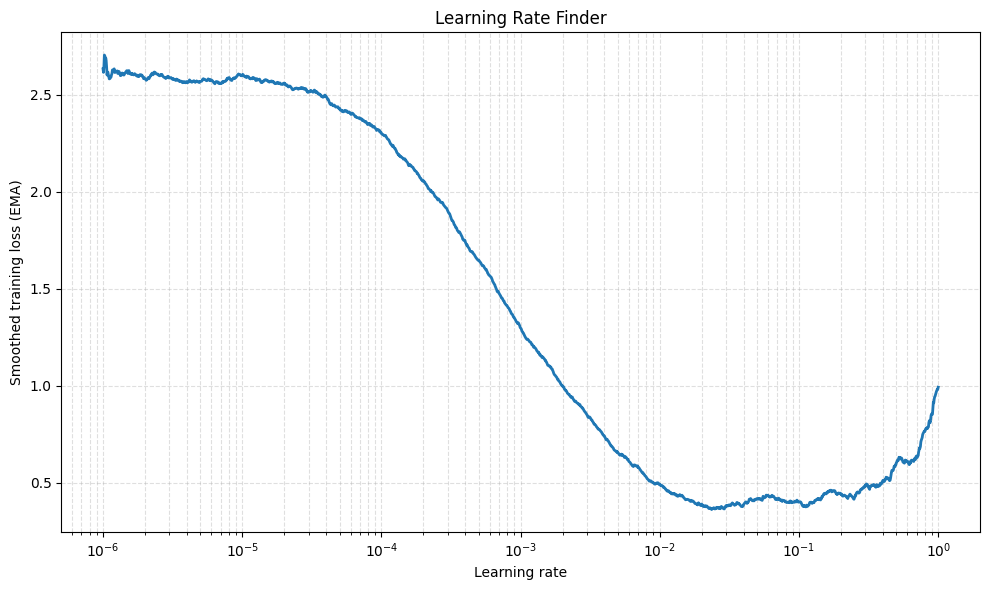

In [74]:
import matplotlib.pyplot as plt

batch_size = 32
torch.manual_seed(1)
model = Mlp()
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, **kwargs
)

lrs, losses = lr_finder(model, device, train_loader)

plt.figure(figsize=(10, 6))
plt.plot(lrs, losses, linewidth=2)
plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Smoothed training loss (EMA)")
plt.title("Learning Rate Finder")
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [76]:
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

generator = torch.Generator().manual_seed(1)
train_subset, val_subset = torch.utils.data.random_split(
    train_dataset, [train_size, val_size], generator=generator
)

train_loader = torch.utils.data.DataLoader(
    train_subset, batch_size=batch_size, shuffle=True, **kwargs
)
val_loader = torch.utils.data.DataLoader(
    val_subset, batch_size=batch_size, shuffle=False, **kwargs
)

experiments = [
    {"name": "conservative", "lr": 1e-3},
    {"name": "aggressive", "lr": 1e-2},
]

log_interval = 80
visualizer = TrainingVisualizer(log_interval)

for exp in experiments:
    print(f"\n--- Trening: {exp['name']} ---")
    torch.manual_seed(1)

    model = Mlp().to(device)
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=exp["lr"],
        momentum=0.9,
        weight_decay=1e-4,
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
        eta_min=1e-5,
    )

    visualizer.track_model(model, optimizer, exp["lr"])

    for epoch in range(1, epochs + 1):
        train_epoch(
            model,
            device,
            train_loader,
            optimizer,
            epoch,
            log_interval,
            visualizer,
            verbose=True,
        )
        test(model, device, val_loader, epoch, visualizer, verbose=True)
        scheduler.step()

FigureWidget({
    'data': [{'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '8f6bbba4-f33f-4e39-a1f9-b8c44057e9f4',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'd50528a8-ba7c-4a08-bf74-660c1b71271f',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '08176ea8-b71a-436a-a5d2-596bbdafed75',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '906a7ce7-6913-47ae-9af7-96b43c522345',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'c7ae22b9-3c37-4e36-aa26-7676ea5556d8',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
     

FigureWidget({
    'data': [{'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'bd607a94-9d25-4580-8715-5070e6afd029',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '4785468f-c633-446e-b1f4-b2d3093a8a78',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '4e7f60e3-e66a-43c0-baa1-7751bb948cff',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'cfb2aad0-80fd-4f0c-bce9-3339b4bd6db4',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'aa9d8512-7481-4a99-8d10-3717a9dd0764',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
     

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '4ddb5665-1191-4fef-997b-daf660e72723',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '64913ba1-4778-4281-9d21-e9f25811ef8b',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '71a794c8-6488-445a-a5c0-9424d18e9e90',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '9ae8e3ee-59a1-4e3c-ba48-af11ee2d7951',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '9


--- Trening: conservative ---
Train Epoch: 1 [0/48000 images (0%)]	Loss: 2.457411
Train Epoch: 1 [2560/48000 images (5%)]	Loss: 1.468959
Train Epoch: 1 [5120/48000 images (11%)]	Loss: 0.967773
Train Epoch: 1 [7680/48000 images (16%)]	Loss: 0.924713
Train Epoch: 1 [10240/48000 images (21%)]	Loss: 0.764619
Train Epoch: 1 [12800/48000 images (27%)]	Loss: 0.649628
Train Epoch: 1 [15360/48000 images (32%)]	Loss: 0.491947
Train Epoch: 1 [17920/48000 images (37%)]	Loss: 0.511428
Train Epoch: 1 [20480/48000 images (43%)]	Loss: 0.498705
Train Epoch: 1 [23040/48000 images (48%)]	Loss: 0.884724
Train Epoch: 1 [25600/48000 images (53%)]	Loss: 0.383521
Train Epoch: 1 [28160/48000 images (59%)]	Loss: 0.354735
Train Epoch: 1 [30720/48000 images (64%)]	Loss: 0.345141
Train Epoch: 1 [33280/48000 images (69%)]	Loss: 0.342247
Train Epoch: 1 [35840/48000 images (75%)]	Loss: 0.406959
Train Epoch: 1 [38400/48000 images (80%)]	Loss: 0.305163
Train Epoch: 1 [40960/48000 images (85%)]	Loss: 0.242020
Train Epo

In [97]:
aug_transform = transforms.Compose([
    transforms.RandomAffine(
        degrees=7,
        translate=(0.08, 0.08),
        scale=(0.95, 1.05),
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.1307,), std=(0.3081,)),
])

train_dataset = datasets.MNIST(
    "../data", train=True, download=True, transform=aug_transform
)

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, **kwargs
)

In [98]:
epochs = 30
lr = 1e-2
log_interval = 320
visualizer = TrainingVisualizer(log_interval)

torch.manual_seed(1)
model = Mlp().to(device)
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=lr,
    momentum=0.9,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=1e-5,
)

visualizer.track_model(model, optimizer, lr)

for epoch in range(1, epochs + 1):
    train_epoch(
        model,
        device,
        train_loader,
        optimizer,
        epoch,
        log_interval,
        visualizer,
        verbose=True,
    )
    test(model, device, test_loader, epoch, visualizer, verbose=True)
    scheduler.step()

FigureWidget({
    'data': [{'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '6f12814b-7fb5-49e3-9c5e-77d6e6cabe39',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'a7ccb11b-eca7-4d0e-9ed4-c9880336ab6a',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'b795f4d6-0c42-4b22-a81b-ed7de4f0e6f0',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'f7dae12c-15b0-4a82-9a2e-690db429a524',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'db097479-69e3-4205-818d-03dd413d7b59',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
     

FigureWidget({
    'data': [{'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'c9ea70dd-a409-49a3-b435-b26d878da5a8',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '1b46b883-a993-45c2-8c85-e3edd165e284',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '69e59da3-adc4-4ebd-b681-bedd64b9f9e5',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '5fd00e47-b311-4c3c-8ca0-fa6da74ea0da',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
              'type': 'scatter',
              'uid': '1e76d26b-a268-4d22-9e6f-5449717dac05',
              'y': []},
             {'mode': 'lines',
              'showlegend': True,
     

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '25afa34c-3795-4a38-924b-25c438008a3f',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '2e4af609-a951-4ec0-8d3f-6205a6106371',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '5f5f2dcf-e3a8-4c0f-90d3-0c8e9b477f01',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': '3600c010-f2e1-4482-a44f-307dfd71e5bc',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'd

Train Epoch: 1 [0/60000 images (0%)]	Loss: 2.350363
Train Epoch: 1 [10240/60000 images (17%)]	Loss: 0.455876
Train Epoch: 1 [20480/60000 images (34%)]	Loss: 0.558620
Train Epoch: 1 [30720/60000 images (51%)]	Loss: 0.112957
Train Epoch: 1 [40960/60000 images (68%)]	Loss: 0.464391
Train Epoch: 1 [51200/60000 images (85%)]	Loss: 0.530576

Test loss: 0.1332, Accuracy: 9624/10000 (96%)

Train Epoch: 2 [0/60000 images (0%)]	Loss: 0.145693
Train Epoch: 2 [10240/60000 images (17%)]	Loss: 0.348219
Train Epoch: 2 [20480/60000 images (34%)]	Loss: 0.255221
Train Epoch: 2 [30720/60000 images (51%)]	Loss: 0.149193
Train Epoch: 2 [40960/60000 images (68%)]	Loss: 0.325610
Train Epoch: 2 [51200/60000 images (85%)]	Loss: 0.182416

Test loss: 0.0925, Accuracy: 9697/10000 (97%)

Train Epoch: 3 [0/60000 images (0%)]	Loss: 0.063468
Train Epoch: 3 [10240/60000 images (17%)]	Loss: 0.163325
Train Epoch: 3 [20480/60000 images (34%)]	Loss: 0.038793
Train Epoch: 3 [30720/60000 images (51%)]	Loss: 0.137561
Train E